# CatBoost. Масштабирование цели и новые признаки

Обучаем восемь моделей на всех получасовых стартах с известной меткой. Подбор, локальный test и сабмит используют старт в 10:30. При обучении цель делится на 100 000, оценка выполняется в исходных единицах.

К исходным уровням добавлены календарь, комбинации статусов, лаги и корреляционный признак маршрута. `warehouse_total_load`, `hub_buffer` и `hub_gate_bottleneck` обозначают формулы из статусов. Их интерпретация как физических нагрузок отдельно не проверялась.

Корреляционный лаг подбирается на train, перед финальным обучением пересчитывается на всей истории. В конце сохраняются важности CatBoost и результаты перестановки признаков для оценочных моделей.

Для обучения включите GPU в Kaggle.


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

DATA = Path("/kaggle/input/datasets/stepzak/")
TRAIN_FILE = Path("train-solo-track/train_solo_track.parquet")
TEST_FILE = Path("test-solo-track/test_solo_track.parquet")
if not (DATA / TRAIN_FILE).is_file() and Path("/kaggle/input").exists():
    matches = [p.parent for p in Path("/kaggle/input").rglob(TRAIN_FILE)
               if (p.parent / TEST_FILE).is_file()]
    if len(matches) != 1:
        raise ValueError(f"Укажите DATA вручную. Найденные папки: {matches}")
    DATA = matches[0]
OUT = Path("artifacts/team_scaled_corr_v2/features")
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "target_1h"
STATUSES = [f"status_{i}" for i in range(1, 7)]
STEP = pd.Timedelta(minutes=30)

# Порог корреляции — настраиваемая эвристика, не тест значимости.
LAG_MAX_LOOKBACK_HOURS = 24
LAG_MIN_PAIRS = 336  # минимум неделя сопоставленных получасовых точек
LAG_MIN_CORRELATION = 0.05
PERMUTATION_ENABLED = True
PERMUTATION_TOP_N = 10
PERMUTATION_REPEATS = 3
PERMUTATION_MAX_DAYS = 7  # целые панели всех маршрутов, без случайного отбора строк
FEATURE_PIPELINE_VERSION = "team_scaled_corr_v2"

## Получасовая сетка
Проверяем полноту панели перед использованием позиционных лагов. Строки массивов - моменты времени, столбцы - маршруты.


In [7]:
history = pd.read_parquet(DATA / TRAIN_FILE, columns=["route_id", "timestamp", TARGET, *STATUSES]).sort_values(["timestamp", "route_id"])
test = pd.read_parquet(DATA / TEST_FILE, columns=["id", "route_id", "timestamp"])
times = pd.DatetimeIndex(history.timestamp.unique())
routes = np.sort(history.route_id.unique())
if not (history.notna().all().all() and test.notna().all().all()):
    raise ValueError("В данных есть пропуски")
if not (not history.duplicated(["route_id", "timestamp"]).any()):
    raise ValueError("Повторяется ключ маршрута и времени")
if not (times.equals(pd.date_range(times[0], times[-1], freq=STEP))):
    raise ValueError("Нарушена получасовая сетка")
if not (len(history) == len(times) * len(routes)):
    raise ValueError("Неполная панель маршрутов")
if not (test.id.is_unique and not test.duplicated(["route_id", "timestamp"]).any()):
    raise ValueError("Повторы идентификаторов или ключей теста")
end = times[-1]
if not ((end.hour, end.minute) == (10, 30)):
    raise ValueError("Последняя точка истории должна быть в 10:30")
expected = pd.MultiIndex.from_product([routes, [end + h*STEP for h in range(1, 9)]],
                                      names=["route_id", "timestamp"])
if not (expected.difference(pd.MultiIndex.from_frame(test[["route_id", "timestamp"]])).empty):
    raise ValueError("Тест не покрывает все ожидаемые маршруты и горизонты")
if not (len(test) == len(expected)):
    raise ValueError("Число строк теста отличается от ожидаемого")
values = {name: history[name].to_numpy(dtype=np.float32).reshape(len(times), len(routes))
          for name in [TARGET, *STATUSES]}
del history
if not all(np.isfinite(array).all() for array in values.values()):
    raise ValueError("В числовых рядах есть бесконечные значения")

# Границы определяются до fit любых статистик, использующих target.
dates = times[(times.hour == 10) & (times.minute == 30) & (times + 8 * STEP <= end)]
if len(dates) <= 28:
    raise ValueError("Недостаточно дат для временного разбиения")
tune_start, holdout_start = dates[-28], dates[-14]
LAG_VALIDATION_FIT_BEFORE = tune_start.normalize()

## Исторические признаки

`origin` обозначает последнюю известную точку. Лаг `k` равен `origin - k` получасовых шагов. Сохраняются `target_back_0/1/2/4`, ускорение `target_back_1 - target_back_2` и недельный лаг `target_1h_lag_336`.

Окно соседних значений ограничено собственным стартом прогноза. Одинаковые источники объединяются. Для суточных и сезонных лагов используются исторические слоты. Недоступная история остаётся NaN.


In [8]:
import pyarrow as pa
import pyarrow.parquet as pq

target = values[TARGET]

def past(array, positions):
    positions = np.asarray(positions, dtype=np.int64)
    valid = (positions >= 0) & (positions < len(array))
    result = array[np.clip(positions, 0, len(array) - 1)].astype(np.float32)
    result[~valid] = np.nan
    return result

def average_available(matrices):
    total = np.zeros_like(matrices[0], dtype=np.float32)
    count = np.zeros_like(total)
    for matrix in matrices:
        valid = np.isfinite(matrix)
        total += np.where(valid, matrix, 0)
        count += valid
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def rolling(array, steps):
    return pd.DataFrame(array).rolling(steps, min_periods=1).mean().to_numpy(dtype=np.float32)

means = {(name, steps): rolling(array, steps)
         for name, array in values.items() for steps in (4, 12)}
level24 = rolling(target, 48)
positions = np.arange(len(times))
extra_signals = {}
for name in STATUSES[:3]:
    extra_signals[name + "_hourly"] = values[name] + past(values[name], positions - 1)
extra_signals["warehouse_total_load"] = sum(extra_signals[name + "_hourly"] for name in STATUSES[:3])
extra_signals["warehouse_processing_rate"] = (
    extra_signals["status_3_hourly"] / (extra_signals["status_1_hourly"] + np.float32(1e-5)))
for name in STATUSES[3:]:
    extra_signals[name + "_diff_hourly"] = values[name] - past(values[name], positions - 2)
extra_signals["hub_buffer"] = values["status_5"] - values["status_4"]
extra_signals["hub_gate_bottleneck"] = (
    extra_signals["status_4_diff_hourly"] - extra_signals["status_6_diff_hourly"])
extra_signals["target_acceleration"] = past(target, positions - 1) - past(target, positions - 2)
hub_signal = extra_signals["status_6_diff_hourly"]

def common_features(origins):
    common = {}
    for k in (0, 1, 2, 4):
        common[f"target_back_{k}"] = past(target, origins - k)
    for name, array in values.items():
        for steps in (4, 12):
            common[f"{name}_mean_{steps}"] = means[name, steps][origins]
        if name in STATUSES:
            common[f"{name}_latest"] = array[origins]
            if name in STATUSES[:3]:
                common[f"{name}_change_1h"] = array[origins] - past(array, origins - 2)
    for name, array in extra_signals.items():
        common[name] = array[origins]
    for lag in (48, 96):
        common[f"target_1h_lag_{lag}"] = past(target, origins - lag)
    common["warehouse_total_load_lag_48"] = past(extra_signals["warehouse_total_load"], origins - 48)
    common["status_6_diff_hourly_lag_48"] = past(hub_signal, origins - 48)
    common["target_vs_mean_6h"] = target[origins] - means[TARGET, 12][origins]
    recent = means[TARGET, 4][origins]
    usual = average_available([past(means[TARGET, 4], origins - day*48) for day in range(1, 8)])
    common["morning_level_ratio"] = np.divide(
        recent, usual, out=np.full_like(recent, np.nan), where=usual > 0)
    return common

CORRELATION_COLUMNS = ["selected_status6_lag_steps", "selected_status6_correlation",
                       "selected_status6_pair_count", "status6_lag_valid",
                       "lagged_status6_signal", "lagged_status6_signal_available"]
FEATURE_GROUPS = {
    "calendar": ["hour", "minute", "hour_float", "hour_sin", "hour_cos", "dayofweek",
                 "is_weekend", "weekday_sin", "weekday_cos"],
    "local_statuses": ["status_1_hourly", "status_2_hourly", "status_3_hourly",
                       "warehouse_total_load", "warehouse_processing_rate"],
    "hub_combinations": ["status_4_diff_hourly", "status_5_diff_hourly", "status_6_diff_hourly",
                         "hub_buffer", "hub_gate_bottleneck"],
    "historical_lags": ["target_1h_lag_48", "target_1h_lag_96",
                        "warehouse_total_load_lag_48", "status_6_diff_hourly_lag_48"],
    "target_change": ["target_acceleration"],
    "correlation_lag": CORRELATION_COLUMNS,
}

## Корреляционный лаг маршрута

Для каждого маршрута ищем Pearson-корреляцию между целью и изменением `status_6` со сдвигами от 2 до 48 получасов. Требуются минимум 336 пар и корреляция не ниже 0,05. При недостатке данных или слабой связи сохраняются NaN и флаг 0.

Для оценки словарь рассчитывается по данным до `LAG_VALIDATION_FIT_BEFORE`. Если найденный лаг равен L, горизонту h нужен сигнал `origin + h - L`. Он доступен при `L >= h`.

Перед финальным обучением словарь пересчитывается на всей истории. Для оценки важности признаков используются прежний словарь и модели до переобучения.


In [9]:
def calculate_dynamic_shoulder(target_values, status6_diff, timestamps, route_ids, *,
                               fit_before, max_lookback_hours=24,
                               min_pairs=336, min_correlation=0.05, route_block_size=128):
    """Обучить статистический лаг маршрута на timestamp < fit_before; без print и мутации входов."""
    grid = pd.DatetimeIndex(timestamps)
    route_ids = np.asarray(route_ids)
    target_values, status6_diff = np.asarray(target_values), np.asarray(status6_diff)
    if target_values.shape != status6_diff.shape or target_values.shape != (len(grid), len(route_ids)):
        raise ValueError("Ожидаются два массива [время, маршрут] одной формы")
    if len(grid) == 0 or not grid.equals(pd.date_range(grid[0], periods=len(grid), freq=STEP)):
        raise ValueError("Для выбора лага нужна упорядоченная получасовая сетка без дубликатов")
    if len(np.unique(route_ids)) != len(route_ids):
        raise ValueError("Идентификаторы маршрутов повторяются")
    steps = float(max_lookback_hours) * 2
    if not np.isfinite(steps) or steps < 2 or not steps.is_integer():
        raise ValueError("Граница поиска должна задавать целое число получасов, не меньше двух")
    if not isinstance(min_pairs, (int, np.integer)) or min_pairs < 3:
        raise ValueError("min_pairs должен быть целым числом >=3")
    if not 0 <= min_correlation <= 1 or route_block_size < 1:
        raise ValueError("Некорректные параметры выбора корреляции")
    max_lag = int(steps)
    stop = int(grid.searchsorted(pd.Timestamp(fit_before), side="left"))
    # Первые две точки diff(2) неизвестны; общие якоря одинаковы для всех L.
    anchors = np.arange(max_lag + 2, stop)
    best_corr = np.full(len(route_ids), np.nan)
    best_lag = np.full(len(route_ids), np.nan)
    best_pairs = np.zeros(len(route_ids), dtype=np.int32)
    for start in range(0, len(route_ids), route_block_size):
        finish = min(start + route_block_size, len(route_ids))
        x = target_values[anchors, start:finish].astype(np.float64)
        for lag in range(2, max_lag + 1):
            z = status6_diff[anchors - lag, start:finish].astype(np.float64)
            valid = np.isfinite(x) & np.isfinite(z)
            count = valid.sum(axis=0)
            xx, zz = np.where(valid, x, 0), np.where(valid, z, 0)
            divisor = np.maximum(count, 1)
            sx, sz = xx.sum(axis=0), zz.sum(axis=0)
            covariance = (xx * zz).sum(axis=0) - sx * sz / divisor
            vx = np.maximum((xx * xx).sum(axis=0) - sx * sx / divisor, 0)
            vz = np.maximum((zz * zz).sum(axis=0) - sz * sz / divisor, 0)
            denominator = np.sqrt(vx * vz)
            corr = np.divide(covariance, denominator, out=np.full(finish-start, np.nan),
                             where=(count >= min_pairs) & (denominator > 0))
            corr = np.clip(corr, -1, 1)
            previous = best_corr[start:finish]
            better = np.isfinite(corr) & (~np.isfinite(previous) | (corr > previous))
            best_corr[start:finish][better] = corr[better]
            best_lag[start:finish][better] = lag
            best_pairs[start:finish][better] = count[better]
    accepted = np.isfinite(best_corr) & (best_corr > min_correlation)
    return pd.DataFrame({"route_id": route_ids,
                         "selected_status6_lag_steps": np.where(accepted, best_lag, np.nan),
                         "selected_status6_correlation": best_corr,
                         "selected_status6_pair_count": best_pairs,
                         "status6_lag_valid": accepted.astype(np.int8)})

def add_correlation_features(frame, h, lag_table, chunk_rows=200_000):
    """Применить готовый словарь; источник каждого значения <= собственного origin."""
    if h not in range(1, 9) or chunk_rows < 1:
        raise ValueError("Некорректный горизонт или размер блока")
    by_route = lag_table.set_index("route_id").reindex(routes)
    route_index = pd.Index(routes)
    lag = by_route.selected_status6_lag_steps.to_numpy(dtype=np.float32)
    quality = {name: by_route[name].to_numpy(dtype=np.float32) for name in CORRELATION_COLUMNS[:4]}
    for name in CORRELATION_COLUMNS:
        frame[name] = np.full(len(frame), np.nan, dtype=np.float32)
    column_positions = {name: frame.columns.get_loc(name) for name in CORRELATION_COLUMNS}
    for start in range(0, len(frame), chunk_rows):
        finish = min(start + chunk_rows, len(frame))
        block = frame.iloc[start:finish]
        origin = times.get_indexer(pd.DatetimeIndex(block.cutoff))
        route = route_index.get_indexer(block.route_id)
        if (origin < 0).any() or (route < 0).any():
            raise ValueError("Строка признаков не сопоставлена с историей")
        selected = lag[route]
        source = origin + h - np.nan_to_num(selected, nan=0).astype(np.int64)
        available = (np.isfinite(selected) & (selected >= h) & (source >= 0)
                     & (source <= origin) & (source < len(times)))
        signal = hub_signal[np.clip(source, 0, len(times)-1), route].astype(np.float32)
        available &= np.isfinite(signal)
        for name, array in quality.items():
            frame.iloc[start:finish, column_positions[name]] = array[route]
        frame.iloc[start:finish, column_positions["lagged_status6_signal"]] = np.where(available, signal, np.nan)
        frame.iloc[start:finish, column_positions["lagged_status6_signal_available"]] = available.astype(np.float32)
    return frame

validation_lag_table = calculate_dynamic_shoulder(
    target, hub_signal, times, routes, fit_before=LAG_VALIDATION_FIT_BEFORE,
    max_lookback_hours=LAG_MAX_LOOKBACK_HOURS, min_pairs=LAG_MIN_PAIRS,
    min_correlation=LAG_MIN_CORRELATION)
validation_lag_table.to_csv(OUT.parent / "status6_lags_validation.csv", index=False)
(OUT.parent / "feature_pipeline.json").write_text(json.dumps({
    "version": FEATURE_PIPELINE_VERSION,
    "validation_lag_fit_before": str(LAG_VALIDATION_FIT_BEFORE),
    "max_lookback_hours": LAG_MAX_LOOKBACK_HOURS, "min_pairs": LAG_MIN_PAIRS,
    "min_correlation": LAG_MIN_CORRELATION,
    "correlation_groups": FEATURE_GROUPS,
}, ensure_ascii=False, indent=2))

1185

## Календарь будущего слота и сохранение
Календарные признаки относятся к прогнозируемому timestamp, а статусы и общие исторические признаки - к origin. Добавлены hour/minute/hour_float, hour_sin/hour_cos, dayofweek и is_weekend. Прежние half_hour_sin/cos заменены эквивалентными hour_sin/cos без дублирования; weekday_sin/cos сохранены.

target_1h_lag_48/96 - сутки/двое назад относительно origin. Отдельные slot_days_back_1/2 - сутки/двое назад относительно будущего слота, они уже существовали и также сохранены. profile28 и overlap по-прежнему используются только постобработкой. Исторические parquet содержат признаки с train-словарём корреляционных лагов; финальная модель заменит только эти колонки в памяти.


In [10]:
def horizon_dataset(h, origins):
    slot = origins + h
    dates = times[origins] + h * STEP
    frame = pd.DataFrame({
        "cutoff": times[origins].repeat(len(routes)),
        "timestamp": dates.repeat(len(routes)),
        "route_id": np.tile(routes, len(origins)),
    })
    for name, matrix in common_features(origins).items():
        frame[name] = matrix.ravel()
    calendar = {
        "hour": dates.hour, "minute": dates.minute,
        "hour_float": dates.hour + dates.minute / 60.0,
        "dayofweek": dates.dayofweek, "is_weekend": (dates.dayofweek >= 5).astype(np.int8),
    }
    calendar["hour_sin"] = np.sin(2 * np.pi * calendar["hour_float"] / 24)
    calendar["hour_cos"] = np.cos(2 * np.pi * calendar["hour_float"] / 24)
    calendar["weekday_sin"] = np.sin(2 * np.pi * dates.dayofweek / 7)
    calendar["weekday_cos"] = np.cos(2 * np.pi * dates.dayofweek / 7)
    for name, array in calendar.items():
        frame[name] = np.repeat(array, len(routes))
    frame = add_correlation_features(frame, h, validation_lag_table)
    for days in (1, 2, 7):
        frame[f"slot_days_back_{days}"] = past(target, slot - days*48).ravel()
    for name, days in [("slot_daily7", range(1, 8)), ("slot_weekly4", (7, 14, 21, 28))]:
        frame[name] = average_available([past(target, slot - d*48) for d in days]).ravel()
    profile = np.zeros((len(origins), len(routes)))
    counts = np.zeros_like(profile)
    for day in range(1, 29):
        level = past(level24, origins - day*48)
        adjusted = past(target, slot - day*48) * level24[origins] / np.maximum(level, 1)
        profile += np.nan_to_num(adjusted)
        counts += np.isfinite(adjusted)
    frame["profile28"] = np.divide(profile, counts, out=np.full_like(profile, np.nan), where=counts > 0).ravel()
    if h == 1:
        lower = np.zeros_like(target[origins])
        upper = past(target, origins - 2)
        for position in (origins - 1, origins):
            total = past(target, position)
            lower, upper = np.maximum(0, total - upper), np.minimum(total, total - lower)
        seasonal = frame[["slot_daily7", "slot_weekly4"]].mean(axis=1).to_numpy()
        frame["overlap"] = np.where((lower <= upper).ravel(),
                                    (lower + upper).ravel() / 2 + seasonal / 2, seasonal)
    else:
        frame["overlap"] = np.nan
    numeric = frame.columns.difference(["cutoff", "timestamp", "route_id"])
    return frame.astype({name: "float32" for name in numeric})

def write_horizon(h):
    stop = len(times) - h
    path = OUT / f"history_h{h}.parquet"
    temporary = path.with_suffix(".partial")
    writer = None
    try:
        for start in range(0, stop, 48):
            origins = np.arange(start, min(start + 48, stop))
            frame = horizon_dataset(h, origins)
            frame["y"] = target[origins + h].ravel()
            table = pa.Table.from_pandas(frame, preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(temporary, table.schema, compression="zstd")
            writer.write_table(table)
    finally:
        if writer is not None:
            writer.close()
    temporary.replace(path)
    features = horizon_dataset(h, np.array([len(times) - 1]))
    requests = test.loc[test.timestamp.eq(end + h*STEP)]
    future = requests.merge(features, on=["route_id", "timestamp"], how="left", validate="one_to_one")
    if not future.cutoff.eq(end).all() or not future.id.equals(requests.id.reset_index(drop=True)):
        raise ValueError("Ошибка сопоставления тестовых строк")
    future.to_parquet(OUT / f"submission_h{h}.parquet", index=False)
    print(f"h={h}: история {stop * len(routes):,}, тест {len(future):,}")

for h in range(1, 9):
    write_horizon(h)

del values, means, level24, extra_signals, positions
# target и hub_signal нужны только для переоценки лагов при финальном refit.

h=1: история 4,629,000, тест 1,000
h=2: история 4,628,000, тест 1,000
h=3: история 4,627,000, тест 1,000
h=4: история 4,626,000, тест 1,000
h=5: история 4,625,000, тест 1,000
h=6: история 4,624,000, тест 1,000
h=7: история 4,623,000, тест 1,000
h=8: история 4,622,000, тест 1,000


## Обучение CatBoost на GPU
Последние 14 размеченных origins 10:30 оставляем для оценки. Предыдущие 14 - для early stopping по MAE. Метки train имеют timestamp до полуночи первого tuning-дня: до первого validation-origin остаётся больше четырёх часов; источник корреляционного словаря ограничен той же границей.

Оценочная модель остаётся замороженной на обоих периодах, как в исходном ноутбуке. После оценки каждая модель переобучается на всей истории с выбранным числом деревьев и новым словарём лагов. Сохранённый отложенный score относится к моделям до refit; это не оценка final-модели на тех же уже обучающих датах. Уже просмотренные даты не являются новым нетронутым holdout.


In [11]:
from catboost import CatBoostRegressor
from catboost.utils import get_gpu_device_count

if get_gpu_device_count() < 1:
    raise RuntimeError("Для обучения включите GPU в настройках Kaggle Notebook.")
MODEL_DIR = OUT.parent / "models"
MODEL_DIR.mkdir(exist_ok=True)
print("Начало подбора:", tune_start, "Начало отложенной проверки:", holdout_start)

def make_model(trees):
    return CatBoostRegressor(iterations=trees, depth=7, learning_rate=0.05,
                             loss_function="MAE", eval_metric="MAE", task_type="GPU",
                             devices="0", cat_features=["route_id"], random_seed=42,
                             allow_writing_files=False, verbose=100)

def mean_daily_score(frame, prediction):
    actual = frame.y.to_numpy(dtype=np.float64)
    errors = np.asarray(prediction, dtype=np.float64) - actual
    totals = pd.DataFrame({"cutoff": frame.cutoff.dt.normalize().to_numpy(), "volume": actual,
                           "error": errors, "absolute": np.abs(errors)}).groupby("cutoff").sum()
    # Дни с нулевой суммой фактов имеют неопределённый score и исключаются из среднего.
    denominator = totals.volume.where(totals.volume > 0)
    return ((totals.absolute + totals.error.abs()) / denominator).mean()

def score_row(frame, predictions, split):
    actual = frame.y.to_numpy(dtype=np.float64)
    errors = np.asarray(predictions, dtype=np.float64) - actual
    volume = actual.sum()
    wape = np.abs(errors).sum() / volume if volume > 0 else np.nan
    signed_bias = errors.sum() / volume if volume > 0 else np.nan
    return {"выборка": split, "даты": frame.cutoff.dt.normalize().nunique(), "строки": len(frame),
            "WAPE": wape, "Relative Bias": signed_bias, "|Relative Bias|": abs(signed_bias),
            "метрика конкурса": wape + abs(signed_bias),
            "среднее по дням": mean_daily_score(frame, predictions)}

TARGET_SCALE = 100_000

def model_columns(data):
    return data.columns.drop(["timestamp", "cutoff", "y", "profile28", "overlap"]).tolist()

split_dates = {"train": dates[dates < tune_start],
               "подбор": dates[(dates >= tune_start) & (dates < holdout_start)],
               "test": dates[dates >= holdout_start]}
display(pd.DataFrame([{"выборка": name, "с": period.min(), "по": period.max(), "даты": len(period)}
                      for name, period in split_dates.items()]))

IMPORTANCE_DIR = OUT.parent / "importance"
IMPORTANCE_DIR.mkdir(exist_ok=True)
builtin_importance_parts = []

def record_builtin_importance(model, columns, h, stage):
    importance = model.get_feature_importance(type="PredictionValuesChange")
    if len(importance) != len(columns):
        raise ValueError("Важности не совпадают с матрицей признаков")
    builtin_importance_parts.append(pd.DataFrame({
        "feature": columns, "importance": importance, "horizon": h, "stage": stage}))

Начало подбора: 2025-10-04 10:30:00 Начало отложенной проверки: 2025-10-18 10:30:00


,выборка,с,по,даты
0,train,2025-07-28 10:30:00,2025-10-03 10:30:00,68
1,подбор,2025-10-04 10:30:00,2025-10-17 10:30:00,14
2,test,2025-10-18 10:30:00,2025-10-31 10:30:00,14


In [13]:
validation_parts = []
tree_counts = {}
evaluation_tables = {}
for h in range(1, 9):
    data = pd.read_parquet(OUT / f"history_h{h}.parquet")
    columns = model_columns(data)
    train = data.timestamp < tune_start.normalize()
    evaluate = data.cutoff.isin(dates[-28:])
    tune = evaluate & (data.cutoff < holdout_start)
    evaluation = data.loc[evaluate, ["cutoff", "timestamp", "route_id", "y", "profile28", "overlap"]].copy()
    evaluation["horizon"] = h
    evaluation["seasonal"] = data.loc[evaluate, ["slot_daily7", "slot_weekly4"]].mean(axis=1)
    model = make_model(1500)
    model.fit(data.loc[train, columns], data.loc[train, "y"] / TARGET_SCALE,
              eval_set=(data.loc[tune, columns], data.loc[tune, "y"] / TARGET_SCALE),
              early_stopping_rounds=100, use_best_model=True)
    tree_counts[h] = model.tree_count_
    model.save_model(str(MODEL_DIR / f"catboost_h{h}_validation.cbm"))
    record_builtin_importance(model, columns, h, "validation_model")
    evaluation["catboost"] = (model.predict(data.loc[evaluate, columns]) * TARGET_SCALE).clip(lower=0)
    test_rows = evaluation.loc[evaluation.cutoff >= holdout_start]
    train_pred = (model.predict(data.loc[train, columns]) * TARGET_SCALE).clip(lower=0)
    table = pd.DataFrame([score_row(data.loc[train], train_pred, "train"),
                          score_row(test_rows, test_rows["catboost"], "test")])
    evaluation_tables[h] = table
    print(f"h={h}, CatBoost, деревьев: {model.tree_count_}")
    display(table)
    del model, data, train_pred
    validation_parts.append(evaluation)
validation = pd.concat(validation_parts, ignore_index=True)
validation.to_parquet(OUT.parent / "validation_predictions.parquet", index=False)

Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2405436	test: 1.4400110	best: 1.4400110 (0)	total: 244ms	remaining: 6m 6s
100:	learn: 0.7612430	test: 0.9011138	best: 0.9011138 (100)	total: 20.7s	remaining: 4m 46s
200:	learn: 0.7001680	test: 0.8017051	best: 0.8017051 (200)	total: 39.7s	remaining: 4m 16s
300:	learn: 0.6881472	test: 0.7802916	best: 0.7802916 (300)	total: 58.4s	remaining: 3m 52s
400:	learn: 0.6828694	test: 0.7732520	best: 0.7732520 (400)	total: 1m 17s	remaining: 3m 32s
500:	learn: 0.6794681	test: 0.7694985	best: 0.7694985 (500)	total: 1m 36s	remaining: 3m 13s
600:	learn: 0.6768475	test: 0.7666402	best: 0.7666402 (600)	total: 1m 56s	remaining: 2m 54s
700:	learn: 0.6744513	test: 0.7641623	best: 0.7641623 (700)	total: 2m 16s	remaining: 2m 35s
800:	learn: 0.6724788	test: 0.7620322	best: 0.7620322 (800)	total: 2m 35s	remaining: 2m 15s
900:	learn: 0.6707643	test: 0.7602533	best: 0.7602533 (900)	total: 2m 55s	remaining: 1m 56s
1000:	learn: 0.6693129	test: 0.7586461	best: 0.7586461 (1000)	total: 3m 14s	remaining: 1m

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3263000,0.260130,-0.035399,0.035399,0.295529,0.296080
1,test,14,14000,0.252126,-0.062616,0.062616,0.314741,0.314561


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2425868	test: 1.4361740	best: 1.4361740 (0)	total: 245ms	remaining: 6m 6s
100:	learn: 0.8779952	test: 1.0076177	best: 1.0076177 (100)	total: 20.3s	remaining: 4m 40s
200:	learn: 0.8433919	test: 0.9535794	best: 0.9535794 (200)	total: 40s	remaining: 4m 18s
300:	learn: 0.8364422	test: 0.9443813	best: 0.9443813 (300)	total: 59s	remaining: 3m 55s
400:	learn: 0.8330981	test: 0.9412214	best: 0.9412214 (400)	total: 1m 18s	remaining: 3m 34s
500:	learn: 0.8307984	test: 0.9398096	best: 0.9398050 (498)	total: 1m 37s	remaining: 3m 15s
600:	learn: 0.8289231	test: 0.9384900	best: 0.9384900 (600)	total: 1m 57s	remaining: 2m 55s
700:	learn: 0.8273675	test: 0.9373220	best: 0.9373220 (700)	total: 2m 16s	remaining: 2m 35s
800:	learn: 0.8260467	test: 0.9363647	best: 0.9363615 (799)	total: 2m 35s	remaining: 2m 16s
900:	learn: 0.8248191	test: 0.9354302	best: 0.9354302 (900)	total: 2m 55s	remaining: 1m 56s
1000:	learn: 0.8237214	test: 0.9346349	best: 0.9346349 (1000)	total: 3m 14s	remaining: 1m 37s

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3262000,0.320955,-0.034925,0.034925,0.355881,0.356422
1,test,14,14000,0.311177,-0.067904,0.067904,0.379081,0.378797


... (14 outputs left out)

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3257000,0.347547,-0.039164,0.039164,0.386711,0.387393
1,test,14,14000,0.339692,-0.056892,0.056892,0.396584,0.395622


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2436508	test: 1.4134745	best: 1.4134745 (0)	total: 230ms	remaining: 5m 44s
100:	learn: 0.9246469	test: 1.0549242	best: 1.0549242 (100)	total: 19.5s	remaining: 4m 30s
200:	learn: 0.8988191	test: 1.0122697	best: 1.0122697 (200)	total: 38.4s	remaining: 4m 8s
300:	learn: 0.8948269	test: 1.0040518	best: 1.0040518 (300)	total: 57s	remaining: 3m 47s
400:	learn: 0.8933407	test: 1.0019605	best: 1.0019605 (400)	total: 1m 15s	remaining: 3m 27s
500:	learn: 0.8924140	test: 1.0010343	best: 1.0010343 (500)	total: 1m 34s	remaining: 3m 8s
600:	learn: 0.8917144	test: 1.0005460	best: 1.0005400 (599)	total: 1m 53s	remaining: 2m 49s
700:	learn: 0.8911523	test: 1.0001543	best: 1.0001543 (700)	total: 2m 12s	remaining: 2m 30s
800:	learn: 0.8906963	test: 0.9998767	best: 0.9998767 (800)	total: 2m 31s	remaining: 2m 12s
900:	learn: 0.8902785	test: 0.9995134	best: 0.9995128 (896)	total: 2m 50s	remaining: 1m 53s
1000:	learn: 0.8899023	test: 0.9992060	best: 0.9992015 (999)	total: 3m 9s	remaining: 1m 34s


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3256000,0.347916,-0.039331,0.039331,0.387247,0.387865
1,test,14,14000,0.338009,-0.069220,0.069220,0.407229,0.406085


## Смешивание и калибровка
Подбираем общий вес модели и множитель на ранних проверочных датах. Сравниваем исходные и скорректированные прогнозы на последних 14 датах. Для submission используем настройки раннего периода. Оценка каждой даты объединяет все 8 горизонтов и все маршруты.


In [14]:
def blend(frame, weight):
    return weight * frame.catboost + (1 - weight) * frame.seasonal

tuning = validation.loc[validation.cutoff < holdout_start]
holdout = validation.loc[validation.cutoff >= holdout_start]
candidates = []
for w in np.linspace(0, 1, 21):
    mixed = blend(tuning, w)
    for k in (1.0, tuning.y.sum() / mixed.sum()):
        candidates.append((mean_daily_score(tuning, mixed * k), w, k))
_, weight, factor = min(candidates)
print(f"Вес CatBoost: {weight:.2f}, множитель: {factor:.4f}")
for label, prediction in [("Сезонный", holdout.seasonal), ("CatBoost", holdout.catboost),
                          ("Смесь", blend(holdout, weight)),
                          ("Смесь с калибровкой", blend(holdout, weight) * factor)]:
    print(f"{label}: {mean_daily_score(holdout, prediction):.5f}")

Параметры, выбранные только на tuning: {'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'additive', 'calib_val': 7635.213337916704}
Средний дневной score на tuning: 0.34386


,w,overlap,p_weight,calib_type,calib_val,tuning_score
671,1.0,False,0.3,additive,7635.213338,0.343857
670,1.0,False,0.3,multiplicative,1.026755,0.343914
674,1.0,False,0.4,additive,6365.924544,0.343936
673,1.0,False,0.4,multiplicative,1.022209,0.344002
668,1.0,False,0.2,additive,8904.505711,0.344180
667,1.0,False,0.2,multiplicative,1.031343,0.344246
605,0.9,False,0.3,additive,6455.209726,0.344301
604,0.9,False,0.3,multiplicative,1.022527,0.344307
677,1.0,False,0.5,additive,5096.636173,0.344396
608,0.9,False,0.4,additive,5336.018768,0.344448


## Отложенная оценка и коэффициент для submission
Сначала оцениваем следующие 14 дат с настройками и коэффициентом tuning, сохраняя сравнение с CatBoost, сезонностью и диагностикой суббот. Эти даты уже просматривались при разработке, поэтому оценка называется отложенной локальной.

Затем выбранное семейство калибровки переоценивается на всей 28-дневной OOS-панели только для hidden submission. Новый коэффициент не подставляется назад в отложенный score; исходные прогнозы и tuning-коэффициент сохраняются отдельно. Перенос коэффициента на модель после refit остаётся допущением, которое проверяется на других временных окнах. Нет необходимости повторять обучение, чтобы сравнить эту постобработку по готовым validation-прогнозам.


In [15]:
# Оценка с зафиксированными tuning-параметрами: до переоценки для submission.
raw_holdout_pred = get_raw_full_prediction(
    holdout, best_config["w"], best_config["overlap"], best_config["p_weight"])
final_holdout_pred = apply_final_calibration(
    raw_holdout_pred, best_config["calib_type"], best_config["calib_val"])

holdout_metrics = pd.DataFrame([
    score_row(holdout, holdout.seasonal, "сезонный"),
    score_row(holdout, holdout.catboost, "CatBoost"),
    score_row(holdout, raw_holdout_pred, "полная комбинация без калибровки"),
    score_row(holdout, final_holdout_pred, "полная комбинация с tuning-калибровкой"),
])
print("Отложенная локальная оценка: настройки зафиксированы на tuning")
display(holdout_metrics)
holdout_metrics.to_csv(POSTPROCESS_DIR / "holdout_metrics.csv", index=False)

# Сохраняем диагностику overlap/профиля, включая субботы.
# У каждой комбинации свой коэффициент того же семейства, обученный только на tuning.
diagnostic_rows = []
for label, use_overlap, p_weight in [
    ("исходная смесь", False, 0.0),
    ("только замена h1", True, 0.0),
    ("только профиль с выбранным весом", False, best_config["p_weight"]),
    ("выбранная комбинация", best_config["overlap"], best_config["p_weight"]),
]:
    raw = get_raw_full_prediction(tuning, best_config["w"], use_overlap, p_weight)
    value = fit_calibration_value(tuning, raw, best_config["calib_type"])
    if value is None:
        continue
    row = {"вариант": label, "вес профиля": p_weight,
           "подбор": mean_daily_score(tuning, apply_final_calibration(raw, best_config["calib_type"], value))}
    for period, subset in [("проверка", holdout),
                           ("субботы", holdout.loc[holdout.cutoff.dt.dayofweek.eq(5)])]:
        raw = get_raw_full_prediction(subset, best_config["w"], use_overlap, p_weight)
        row[period] = mean_daily_score(subset, apply_final_calibration(raw, best_config["calib_type"], value))
    diagnostic_rows.append(row)
postprocessing_diagnostics = pd.DataFrame(diagnostic_rows)
display(postprocessing_diagnostics)
postprocessing_diagnostics.to_csv(POSTPROCESS_DIR / "overlap_profile_diagnostics.csv", index=False)

# Полные OOS-прогнозы сохраняются со СТАРЫМ tuning-коэффициентом для оценки.
raw_val_pred = get_raw_full_prediction(
    validation, best_config["w"], best_config["overlap"], best_config["p_weight"])
validation_postprocessed = validation.copy()
validation_postprocessed["raw_full_prediction"] = raw_val_pred
validation_postprocessed["y_pred_tuning_calibration"] = apply_final_calibration(
    raw_val_pred, best_config["calib_type"], best_config["calib_val"])
validation_postprocessed.to_parquet(POSTPROCESS_DIR / "validation_postprocessed.parquet", index=False)

# Только для финального hidden submission переоцениваем выбранное семейство на всех 28 датах.
# best_config['calib_val'] остаётся неизменным: оно относится к оценке holdout выше.
submission_calib_val = fit_calibration_value(validation, raw_val_pred, best_config["calib_type"])
if submission_calib_val is None:
    raise ValueError("Нельзя переоценить выбранную калибровку на полной validation-панели")
postprocessing_settings = {
    "selection_metric": "mean_daily_WAPE_plus_abs_relative_bias",
    "best_config": best_config.copy(), "tuning_score": float(best_score),
    "holdout_score": float(mean_daily_score(holdout, final_holdout_pred)),
    "holdout_start": str(holdout_start),
    "submission_calib_val": float(submission_calib_val),
    "submission_calibration_period": [str(validation.cutoff.min()), str(validation.cutoff.max())],
    "target_scale": TARGET_SCALE,
}
(POSTPROCESS_DIR / "settings.json").write_text(
    json.dumps(postprocessing_settings, ensure_ascii=False, indent=2))
print(f"Коэффициент для submission ({best_config['calib_type']}): {submission_calib_val:.6f}")

Отложенная локальная оценка: настройки зафиксированы на tuning


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,сезонный,14,112000,0.354692,0.014552,0.014552,0.369244,0.381694
1,CatBoost,14,112000,0.322482,-0.058178,0.058178,0.380660,0.380399
2,полная комбинация без калибровки,14,112000,0.320965,-0.038548,0.038548,0.359513,0.359835
3,полная комбинация с tuning-калибровкой,14,112000,0.321902,-0.012154,0.012154,0.334056,0.341268


,вариант,вес профиля,подбор,проверка,субботы
0,исходная смесь,0.0,0.345970,0.346001,0.340966
1,только замена h1,0.0,0.348849,0.346697,0.342390
2,только профиль с выбранным весом,0.3,0.343857,0.341268,0.329258
3,выбранная комбинация,0.3,0.343857,0.341268,0.329258


Коэффициент для submission (additive): 9393.172250


In [16]:
early = pd.read_parquet(OUT / "history_h1.parquet")
early = early.loc[early.cutoff.isin(dates[:-28])].copy()
early["seasonal"] = early[["slot_daily7", "slot_weekly4"]].mean(axis=1)
early = early.dropna(subset=["seasonal", "overlap"])
print("Ранняя история, метрика отдельно для h1:")
for name in ("seasonal", "overlap"):
    print(name, mean_daily_score(early, early[name]))
del early

Ранняя история, метрика отдельно для h1:
seasonal 0.42164019575451955
overlap 0.32641052618030514


## Финальное обучение

На всей доступной истории пересчитываем словарь корреляционных лагов и обучаем выбранные модели. Финальные модели и словарь сохраняются отдельно.

После каждого обучения выводится ошибка на полной обучающей истории и сохранённые train/test оценочной модели. Независимая оценка test получена на предыдущем этапе до этого переобучения.


In [18]:
final_lag_table = calculate_dynamic_shoulder(
    target, hub_signal, times, routes, fit_before=end + STEP,
    max_lookback_hours=LAG_MAX_LOOKBACK_HOURS, min_pairs=LAG_MIN_PAIRS,
    min_correlation=LAG_MIN_CORRELATION)
final_lag_table.to_csv(OUT.parent / "status6_lags_final.csv", index=False)
metadata_path = OUT.parent / "feature_pipeline.json"
metadata = json.loads(metadata_path.read_text())
metadata.update(final_lag_fit_before=str(end + STEP), target_scale=TARGET_SCALE)
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
submission_parts = []
for h in range(1, 9):
    data = pd.read_parquet(OUT / f"history_h{h}.parquet")
    future = pd.read_parquet(OUT / f"submission_h{h}.parquet")
    data = add_correlation_features(data, h, final_lag_table)
    future = add_correlation_features(future, h, final_lag_table)
    columns = model_columns(data)
    result = future[["id", "profile28", "overlap"]].copy()
    result["seasonal"] = future[["slot_daily7", "slot_weekly4"]].mean(axis=1)
    result["horizon"] = h
    model = make_model(tree_counts[h])
    model.fit(data[columns], data.y / TARGET_SCALE)
    model.save_model(str(MODEL_DIR / f"catboost_h{h}_scaled.cbm"))
    record_builtin_importance(model, columns, h, "final_model")
        # 1. Считаем сырое предсказание CatBoost для теста конкурса
    raw_cb_future = (model.predict(future[columns]) * TARGET_SCALE).clip(min=0)
    result["catboost"] = raw_cb_future
    
    # 2. Собираем финальную взвешенную комбинацию (Смесь CatBoost + Сезонность)
    future_base = best_config['w'] * raw_cb_future + (1 - best_config['w']) * result["seasonal"]
    
    # 3. Накладываем оверлап для h=1 или профиль для дальних горизонтов h>1
    if best_config['overlap'] and h == 1:
        future_base = result["overlap"]
    elif h > 1:
        future_base = (1 - best_config['p_weight']) * future_base + best_config['p_weight'] * result["profile28"]
    
    # 4. Применяем пересчитанную аддитивную калибровку (9393.17) строго в финале
    result["y_pred"] = apply_final_calibration(future_base, best_config['calib_type'], submission_calib_val)
    
    # Оставляем ваш код логирования на экраны
    full_pred = (model.predict(data[columns]) * TARGET_SCALE).clip(min=0)
    full_row = score_row(data, full_pred, "вся история после переобучения")
    print(f"h={h}, CatBoost: первые две строки — оценка до переобучения")
    display(pd.concat([evaluation_tables[h], pd.DataFrame([full_row])], ignore_index=True))
    
    # Очищаем память и аппендим полный калиброванный результат
    del model, data, future, full_pred

    submission_parts.append(result)

Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2692760	total: 348ms	remaining: 8m 41s
100:	learn: 0.7819651	total: 29.7s	remaining: 6m 51s
200:	learn: 0.7175829	total: 57s	remaining: 6m 8s
300:	learn: 0.7048557	total: 1m 23s	remaining: 5m 32s
400:	learn: 0.6996305	total: 1m 50s	remaining: 5m 3s
500:	learn: 0.6961808	total: 2m 18s	remaining: 4m 35s
600:	learn: 0.6934830	total: 2m 45s	remaining: 4m 8s
700:	learn: 0.6910577	total: 3m 13s	remaining: 3m 40s
800:	learn: 0.6890937	total: 3m 41s	remaining: 3m 13s
900:	learn: 0.6873670	total: 4m 9s	remaining: 2m 45s
1000:	learn: 0.6858411	total: 4m 36s	remaining: 2m 17s
1100:	learn: 0.6844780	total: 5m 3s	remaining: 1m 50s
1200:	learn: 0.6832665	total: 5m 30s	remaining: 1m 22s
1300:	learn: 0.6821928	total: 5m 57s	remaining: 54.8s
1400:	learn: 0.6811860	total: 6m 25s	remaining: 27.2s
1499:	learn: 0.6803047	total: 6m 52s	remaining: 0us
h=1, CatBoost: первые две строки — оценка до переобучения


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3263000,0.260130,-0.035399,0.035399,0.295529,0.296080
1,test,14,14000,0.252126,-0.062616,0.062616,0.314741,0.314561
2,вся история после переобучения,97,4629000,0.260392,-0.036167,0.036167,0.296559,0.296906


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2713270	total: 336ms	remaining: 8m 23s
100:	learn: 0.9004144	total: 28.9s	remaining: 6m 40s
200:	learn: 0.8644242	total: 57.2s	remaining: 6m 9s
300:	learn: 0.8574831	total: 1m 24s	remaining: 5m 35s
400:	learn: 0.8542857	total: 1m 51s	remaining: 5m 5s
500:	learn: 0.8520392	total: 2m 18s	remaining: 4m 37s
600:	learn: 0.8502013	total: 2m 46s	remaining: 4m 8s
700:	learn: 0.8486706	total: 3m 12s	remaining: 3m 39s
800:	learn: 0.8473388	total: 3m 39s	remaining: 3m 11s
900:	learn: 0.8462074	total: 4m 6s	remaining: 2m 43s
1000:	learn: 0.8451463	total: 4m 33s	remaining: 2m 16s
1100:	learn: 0.8441493	total: 4m 59s	remaining: 1m 48s
1200:	learn: 0.8431680	total: 5m 25s	remaining: 1m 21s
1300:	learn: 0.8422810	total: 5m 51s	remaining: 53.8s
1400:	learn: 0.8414887	total: 6m 18s	remaining: 26.7s
1499:	learn: 0.8407821	total: 6m 44s	remaining: 0us
h=2, CatBoost: первые две строки — оценка до переобучения


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3262000,0.320955,-0.034925,0.034925,0.355881,0.356422
1,test,14,14000,0.311177,-0.067904,0.067904,0.379081,0.378797
2,вся история после переобучения,97,4628000,0.321798,-0.036069,0.036069,0.357867,0.358249


... (14 outputs left out)

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3257000,0.347547,-0.039164,0.039164,0.386711,0.387393
1,test,14,14000,0.339692,-0.056892,0.056892,0.396584,0.395622
2,вся история после переобучения,97,4623000,0.347350,-0.040058,0.040058,0.387408,0.387846


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2722951	total: 316ms	remaining: 7m 53s
100:	learn: 0.9465363	total: 27.9s	remaining: 6m 26s
200:	learn: 0.9194771	total: 55.1s	remaining: 5m 55s
300:	learn: 0.9152654	total: 1m 21s	remaining: 5m 23s
400:	learn: 0.9137502	total: 1m 47s	remaining: 4m 53s
500:	learn: 0.9128020	total: 2m 13s	remaining: 4m 25s
600:	learn: 0.9120842	total: 2m 40s	remaining: 3m 58s
700:	learn: 0.9114961	total: 3m 6s	remaining: 3m 32s
800:	learn: 0.9110241	total: 3m 33s	remaining: 3m 6s
900:	learn: 0.9106071	total: 4m 1s	remaining: 2m 40s
1000:	learn: 0.9102439	total: 4m 29s	remaining: 2m 13s
1100:	learn: 0.9099216	total: 4m 57s	remaining: 1m 47s
1200:	learn: 0.9096261	total: 5m 25s	remaining: 1m 20s
1300:	learn: 0.9093638	total: 5m 52s	remaining: 53.4s
1400:	learn: 0.9090945	total: 6m 20s	remaining: 26.4s
1497:	learn: 0.9088601	total: 6m 47s	remaining: 0us
h=8, CatBoost: первые две строки — оценка до переобучения


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,3256000,0.347916,-0.039331,0.039331,0.387247,0.387865
1,test,14,14000,0.338009,-0.069220,0.069220,0.407229,0.406085
2,вся история после переобучения,97,4622000,0.347775,-0.040048,0.040048,0.387822,0.388191


## Итоговый файл для соревнования


In [19]:
# В submission_parts нужны исходные catboost/seasonal, horizon, overlap/profile28 и id.
# Калибровка применяется ровно один раз, ПОСЛЕ объединения восьми горизонтов.
predictions = pd.concat(submission_parts, ignore_index=True)
required = {"id", "horizon", "catboost", "seasonal", "overlap", "profile28"}
if not required.issubset(predictions.columns):
    raise ValueError(f"В submission_parts нет колонок: {sorted(required - set(predictions.columns))}")
if (len(predictions) != len(test) or not predictions.id.is_unique
        or set(predictions.horizon.unique()) != set(range(1, 9))):
    raise ValueError("Нужен ровно один набор прогнозов для каждого из восьми горизонтов")

raw_submission_pred = get_raw_full_prediction(
    predictions, best_config["w"], best_config["overlap"], best_config["p_weight"])
predictions["y_pred"] = apply_final_calibration(
    raw_submission_pred, best_config["calib_type"], submission_calib_val)

submission = test[["id"]].merge(
    predictions[["id", "y_pred"]], on="id", how="left", validate="one_to_one")
if (len(submission) != len(test) or not submission.id.equals(test.id.reset_index(drop=True))
        or not np.isfinite(submission.y_pred).all() or (submission.y_pred < 0).any()):
    raise ValueError("Неполный или некорректный прогноз в submission")
submission.to_csv("submission.csv", index=False)
print(f"submission.csv: {len(submission):,} строк, колонки id,y_pred")
display(submission.head())

submission.csv: 8,000 строк, колонки id,y_pred


,id,y_pred
0,0,91942.429719
1,1,150234.783741
2,2,173369.932644
3,3,160304.164830
4,4,162546.976771


## Важность признаков

`PredictionValuesChange` сохраняется отдельно по восьми горизонтам до и после финального обучения. График показывает среднюю важность финальных моделей. При коррелирующих входах вклад может распределяться между несколькими признаками.


--- ТОП-30 ПРИЗНАКОВ ПО СТАДИЯМ ---


,stage,feature,mean,std
16,final_model,slot_daily7,24.886705,12.272265
52,final_model,target_1h_mean_12,8.937236,8.091135
55,final_model,target_back_0,7.831691,15.029700
31,final_model,status_2_mean_4,7.378445,9.517662
25,final_model,status_1_mean_12,6.826867,6.476342
54,final_model,target_acceleration,3.336556,6.204900
61,final_model,warehouse_total_load,3.019464,4.413687
34,final_model,status_3_latest,2.847915,4.278974
20,final_model,slot_weekly4,2.828081,1.526654
12,final_model,route_id,2.637820,1.502917



--- МАТРИЦА ВАЖНОСТИ ПО ГОРИЗОНТАМ (ТОП-30) ---


horizon,1,2,3,4,5,6,7,8
feature,,,,,,,,
slot_daily7,6.145969,17.544624,23.961045,29.864455,33.188130,34.793294,35.366001,36.970861
target_1h_mean_12,0.437369,0.064705,3.303092,8.545020,13.791539,17.577843,18.861705,17.416484
status_2_mean_4,3.655602,27.337727,18.680195,9.098504,2.898321,0.560661,0.265770,0.253620
status_1_mean_12,0.016987,0.000000,1.388451,7.088309,12.073695,12.981678,13.912695,13.963000
target_back_0,34.331013,1.359000,0.084508,0.052221,0.031580,0.017958,0.039414,0.238510
slot_weekly4,0.473566,1.912470,2.824455,3.488985,3.832498,3.991280,4.199949,4.255955
route_id,0.383423,1.967913,2.767686,2.811121,3.099572,3.506361,4.129490,4.691388
status_1_mean_4,0.000000,0.142739,1.824978,5.079523,4.517215,4.573787,4.058203,2.606582
status_2_hourly,0.117798,8.151653,5.888641,2.479579,2.514842,2.162958,0.682786,0.157788


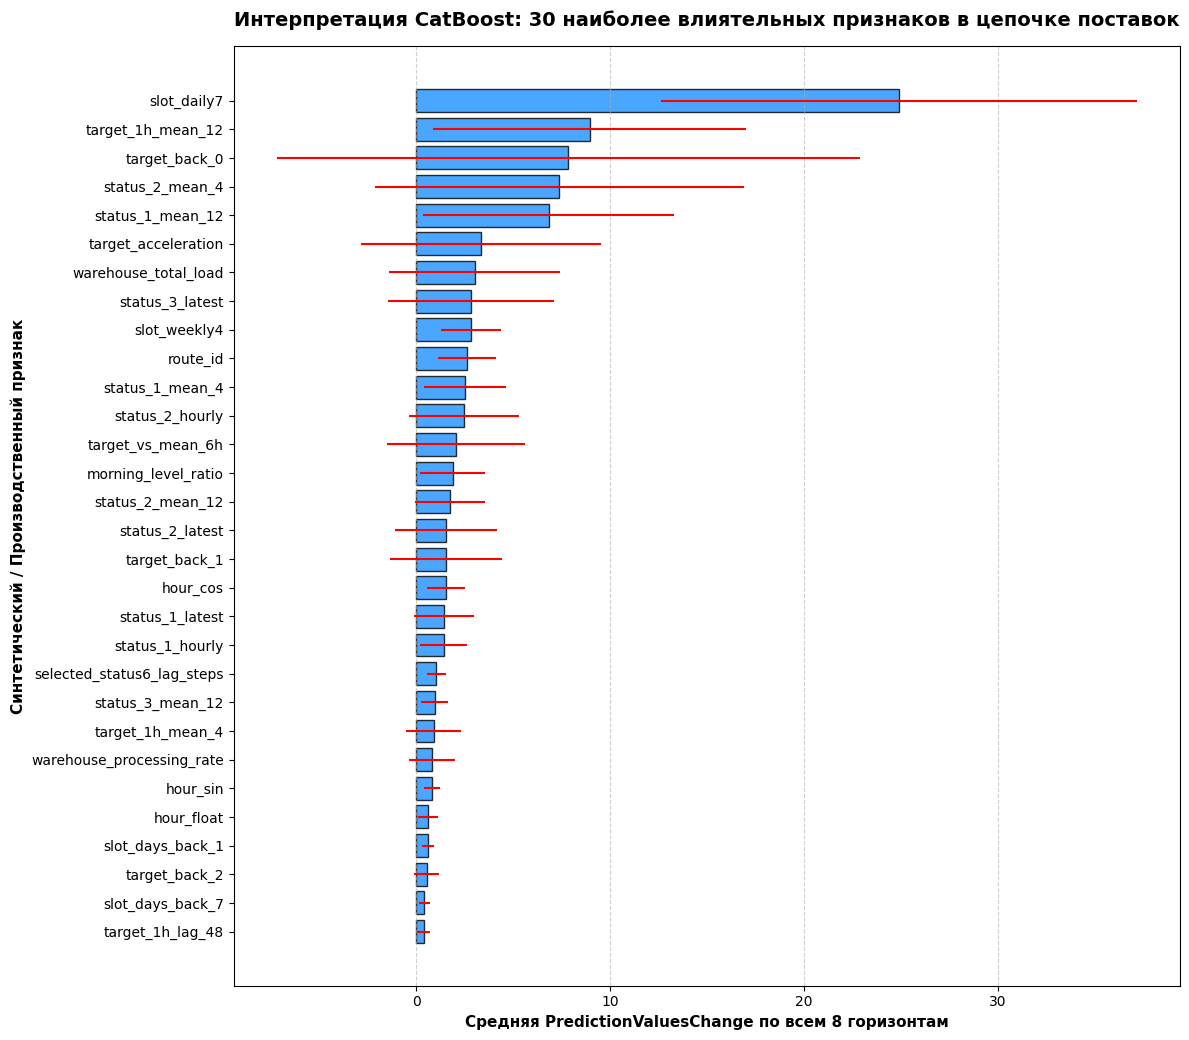

In [22]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Безопасная проверка: если builtin_importance_parts не существует, 
# мы подстрахуемся и попробуем взять логи из папки артефактов
if 'builtin_importance_parts' not in locals() or len(builtin_importance_parts) == 0:
    print("⚠ Переменная builtin_importance_parts пуста. Проверяем сохраненные файлы важности...")
    # Если у вас логи сохранялись в файлы, можно подтянуть их оттуда, 
    # иначе убедитесь, что в ячейке 13 этот массив наполняется!
    builtin_importance = pd.DataFrame()
else:
    builtin_importance = pd.concat(builtin_importance_parts, ignore_index=True)

if not builtin_importance.empty:
    # Создаем директорию для графиков, если её нет
    IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)
    
    # Сохраняем подробные логи по горизонтам
    builtin_importance.to_csv(IMPORTANCE_DIR / "catboost_importance_by_horizon.csv", index=False)
    
    # Агрегируем среднее и стандартное отклонение
    importance_summary = (builtin_importance.groupby(["stage", "feature"])["importance"]
                          .agg(["mean", "std"]).reset_index()
                          .sort_values(["stage", "mean"], ascending=[True, False]))
    importance_summary.to_csv(IMPORTANCE_DIR / "catboost_importance_summary.csv", index=False)
    
    print("--- ТОП-30 ПРИЗНАКОВ ПО СТАДИЯМ ---")
    display(importance_summary.groupby("stage", sort=False).head(30))
    
    # Разворачиваем в матрицу: Фича х Горизонт
    print("\n--- МАТРИЦА ВАЖНОСТИ ПО ГОРИЗОНТАМ (ТОП-30) ---")
    
    # Сначала фильтруем финальную модель
    final_importance = builtin_importance.query("stage == 'final_model'")
    
    # ЗАЩИТА: Группируем по фиче и горизонту и берем среднее (на случай, если логи продублировались)
    final_importance_clean = (final_importance.groupby(["feature", "horizon"])["importance"]
                              .mean().reset_index())
    
    # Теперь разворот матрицы отработает идеально и без ошибок!
    importance_by_horizon = final_importance_clean.pivot(
        index="feature", columns="horizon", values="importance")
    
    # Сортируем фичи по убыванию средней важности по всем горизонтам
    importance_by_horizon = importance_by_horizon.loc[
        importance_by_horizon.mean(axis=1).sort_values(ascending=False).index
    ]
    
    display(importance_by_horizon.head(30))

    
    # Строим финальный график для защиты проекта
    top = importance_summary.query("stage == 'final_model'").head(30).sort_values("mean")
    
    fig, ax = plt.subplots(figsize=(12, max(6, len(top) * 0.35))) # Чуть увеличили шаг по вертикали для читаемости
    
    # Красивый горизонтальный бар с отображением стандартного отклонения (std) в виде усов
    ax.barh(top.feature, top["mean"], xerr=top["std"], color='dodgerblue', alpha=0.8, edgecolor='black', ecolor='red')
    
    ax.set_xlabel("Средняя PredictionValuesChange по всем 8 горизонтам", fontsize=11, weight='bold')
    ax.set_ylabel("Синтетический / Производственный признак", fontsize=11, weight='bold')
    ax.set_title("Интерпретация CatBoost: 30 наиболее влиятельных признаков в цепочке поставок", fontsize=14, weight='bold', pad=15)
    
    # Добавляем сетку для удобства чтения значений на защите
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    fig.tight_layout()
    fig.savefig(IMPORTANCE_DIR / "catboost_top30.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("❌ Ошибка: builtin_importance_parts оказался пуст. Проверьте логирование в ячейке №13.")


## Важность признаков на локальном test

Используем оценочные модели и словарь лагов до финального переобучения. По умолчанию выбраны семь из 14 дат test, все маршруты и горизонты, три повтора и десять наиболее важных признаков. Корреляционные сигналы и новые семейства признаков проверяются также группами.

Переставляются маршрутные траектории с циклическим сдвигом дат. Один индекс применяется ко всем колонкам группы и горизонтам. Положительная `delta_mean_daily_score` означает рост ошибки после перестановки. `horizon=0` объединяет маршруты и горизонты одного дня.

Результат показывает зависимость конкретной модели от входов на этих датах. При отборе признаков по этой таблице потребуется отдельный период проверки.

Описание методов дано в [CatBoost](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_get_feature_importance) и [scikit-learn](https://scikit-learn.org/stable/modules/permutation_importance.html).


Permutation importance: feature / slot_daily7
Permutation importance: feature / status_2_mean_4
Permutation importance: feature / target_1h_mean_12
Permutation importance: feature / status_1_mean_12
Permutation importance: feature / target_back_0
Permutation importance: feature / route_id
Permutation importance: feature / status_2_hourly
Permutation importance: feature / status_1_mean_4
Permutation importance: feature / slot_weekly4
Permutation importance: feature / target_vs_mean_6h
Permutation importance: feature / lagged_status6_signal
Permutation importance: feature / selected_status6_lag_steps
Permutation importance: group / calendar
Permutation importance: group / local_statuses
Permutation importance: group / hub_combinations
Permutation importance: group / historical_lags
Permutation importance: group / target_change
Permutation importance: group / correlation_lag


,kind,name,horizon,delta_mean_daily_score_mean,delta_mean_daily_score_std,delta_pooled_score_mean,delta_pooled_score_std,delta_wape_mean,delta_wape_std,delta_abs_bias_mean,delta_abs_bias_std
27,feature,slot_daily7,0,0.040452,0.001601,0.040448,0.001616,0.027361,0.000787,0.013087,0.000985
72,feature,status_2_mean_4,0,0.023980,0.000077,0.024013,0.000080,0.014976,0.000054,0.009037,0.000031
90,feature,target_back_0,0,0.022914,0.000265,0.022919,0.000265,0.037671,0.000542,-0.014753,0.000287
81,feature,target_1h_mean_12,0,0.019296,0.000434,0.019329,0.000429,0.009641,0.000288,0.009688,0.000211
144,group,local_statuses,0,0.011936,0.000091,0.011994,0.000105,0.010165,0.000137,0.001829,0.000033
9,feature,route_id,0,0.008561,0.000168,0.008567,0.000169,0.004629,0.000094,0.003938,0.000079
36,feature,slot_weekly4,0,0.008513,0.000152,0.008520,0.000150,0.001956,0.000094,0.006564,0.000059
45,feature,status_1_mean_12,0,0.006386,0.000136,0.006420,0.000117,0.003744,0.000042,0.002676,0.000087
63,feature,status_2_hourly,0,0.006204,0.000074,0.006218,0.000071,0.002586,0.000020,0.003632,0.000052
153,group,target_change,0,0.004226,0.000106,0.004219,0.000102,0.005884,0.000124,-0.001665,0.000035


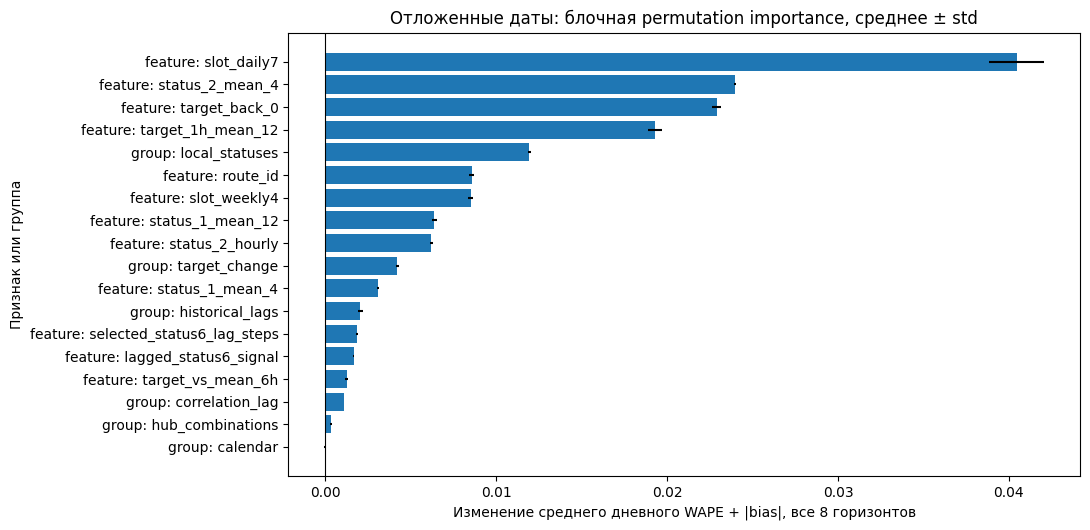

In [23]:
def block_permutation_index(frame, seed):
    """Единая биекция (дата, маршрут); горизонт не входит в перемешиваемую ось."""
    rng = np.random.default_rng(seed)
    days = pd.DatetimeIndex(frame.cutoff.unique()).sort_values()
    route_values = np.sort(frame.route_id.unique())
    keys = pd.MultiIndex.from_frame(frame[["cutoff", "route_id"]])
    if not keys.is_unique or len(frame) != len(days) * len(route_values):
        raise ValueError("Permutation importance требует полную панель дата × маршрут")
    date_shift = int(rng.integers(1, len(days))) if len(days) > 1 else 0
    donor_days = days[np.roll(np.arange(len(days)), date_shift)][days.get_indexer(frame.cutoff)]
    donor_routes = rng.permutation(route_values)[pd.Index(route_values).get_indexer(frame.route_id)]
    donor = keys.get_indexer(pd.MultiIndex.from_arrays([donor_days, donor_routes]))
    if (donor < 0).any() or len(np.unique(donor)) != len(frame):
        raise ValueError("Перестановка не является биекцией")
    return donor

def permutation_deltas(meta_parts, original_parts, shuffled_parts):
    rows = []
    for h, meta, original, shuffled in zip(range(1, 9), meta_parts, original_parts, shuffled_parts):
        before, after = score_row(meta, original, "baseline"), score_row(meta, shuffled, "permuted")
        rows.append({"horizon": h,
                     "delta_mean_daily_score": after["среднее по дням"] - before["среднее по дням"],
                     "delta_pooled_score": after["метрика конкурса"] - before["метрика конкурса"],
                     "delta_wape": after["WAPE"] - before["WAPE"],
                     "delta_abs_bias": after["|Relative Bias|"] - before["|Relative Bias|"]})
    combined = pd.concat(meta_parts, ignore_index=True)
    before = score_row(combined, np.concatenate(original_parts), "baseline")
    after = score_row(combined, np.concatenate(shuffled_parts), "permuted")
    rows.append({"horizon": 0,
                 "delta_mean_daily_score": after["среднее по дням"] - before["среднее по дням"],
                 "delta_pooled_score": after["метрика конкурса"] - before["метрика конкурса"],
                 "delta_wape": after["WAPE"] - before["WAPE"],
                 "delta_abs_bias": after["|Relative Bias|"] - before["|Relative Bias|"]})
    return rows

def run_permutation_importance():
    if PERMUTATION_MAX_DAYS < 2 or PERMUTATION_REPEATS < 2 or PERMUTATION_TOP_N < 1:
        raise ValueError("Для диагностики нужны >=2 даты, >=2 повтора и положительный top-N")
    available_days = dates[dates >= holdout_start]
    pick = np.unique(np.linspace(0, len(available_days)-1,
                                min(PERMUTATION_MAX_DAYS, len(available_days))).round().astype(int))
    selected_days = available_days[pick]
    models, matrices, metadata, original = [], [], [], []
    baseline_rows = []
    for h in range(1, 9):
        model = CatBoostRegressor()
        model.load_model(str(MODEL_DIR / f"catboost_h{h}_validation.cbm"))
        names = model.feature_names_
        read_columns = list(dict.fromkeys(["cutoff", "timestamp", "route_id", "y", *names]))
        frame = pd.read_parquet(OUT / f"history_h{h}.parquet", columns=read_columns,
                                filters=[("cutoff", "in", selected_days.to_pydatetime().tolist())])
        frame = frame.sort_values(["cutoff", "route_id"]).reset_index(drop=True)
        if len(frame) != len(selected_days) * len(routes):
            raise ValueError("Неполная панель отложенных данных для важностей")
        meta = frame[["cutoff", "timestamp", "route_id", "y"]].copy()
        matrix = frame[names].copy()
        prediction = (model.predict(matrix) * TARGET_SCALE).clip(min=0)
        baseline_rows.append({"horizon": h, **score_row(meta, prediction, "permutation_baseline")})
        models.append(model)
        matrices.append(matrix)
        metadata.append(meta)
        original.append(prediction)
    combined = pd.concat(metadata, ignore_index=True)
    baseline_rows.append({"horizon": 0, **score_row(combined, np.concatenate(original), "permutation_baseline")})
    pd.DataFrame(baseline_rows).to_csv(IMPORTANCE_DIR / "permutation_baseline.csv", index=False)
    rank = (builtin_importance.query("stage == 'validation_model'")
            .groupby("feature").importance.mean().sort_values(ascending=False))
    individual = list(dict.fromkeys([*rank.head(PERMUTATION_TOP_N).index,
                                    "lagged_status6_signal", "selected_status6_lag_steps"]))
    specs = [("feature", name, [name]) for name in individual if name in matrices[0].columns]
    specs += [("group", name, [c for c in names if c in matrices[0].columns])
              for name, names in FEATURE_GROUPS.items()]
    specs = [spec for spec in specs if spec[2]]
    (IMPORTANCE_DIR / "permutation_settings.json").write_text(json.dumps({
        "days": [str(d) for d in selected_days], "routes": len(routes),
        "repeats": PERMUTATION_REPEATS, "seed": 42,
        "model_stage": "validation_model", "lag_fit_before": str(LAG_VALIDATION_FIT_BEFORE),
        "specs": [{"kind": kind, "name": name, "columns": columns} for kind, name, columns in specs],
    }, ensure_ascii=False, indent=2))
    rows = []
    for kind, name, columns in specs:
        for repeat in range(PERMUTATION_REPEATS):
            shuffled = []
            for model, matrix, meta in zip(models, matrices, metadata):
                donor = block_permutation_index(meta, seed=42 + repeat)
                permuted = matrix.copy()
                permuted.loc[:, columns] = matrix.iloc[donor][columns].to_numpy()
                shuffled.append((model.predict(permuted) * TARGET_SCALE).clip(min=0))
            for row in permutation_deltas(metadata, original, shuffled):
                rows.append({"kind": kind, "name": name, "repeat": repeat,
                             "n_features": len(columns), **row})
        print(f"Permutation importance: {kind} / {name}")
    detail = pd.DataFrame(rows)
    detail.to_csv(IMPORTANCE_DIR / "permutation_detail.csv", index=False)
    metrics = ["delta_mean_daily_score", "delta_pooled_score", "delta_wape", "delta_abs_bias"]
    summary = detail.groupby(["kind", "name", "horizon"])[metrics].agg(["mean", "std"])
    summary.columns = ["_".join(column) for column in summary.columns]
    summary = summary.reset_index().sort_values("delta_mean_daily_score_mean", ascending=False)
    summary.to_csv(IMPORTANCE_DIR / "permutation_summary.csv", index=False)
    return summary

if PERMUTATION_ENABLED:
    permutation_summary = run_permutation_importance()
    overall = permutation_summary.loc[permutation_summary.horizon.eq(0)].copy()
    display(overall)
    plot = overall.sort_values("delta_mean_daily_score_mean")
    fig, ax = plt.subplots(figsize=(11, max(5, len(plot) * 0.3)))
    ax.barh(plot.kind + ": " + plot.name, plot.delta_mean_daily_score_mean,
            xerr=plot.delta_mean_daily_score_std.fillna(0))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(xlabel="Изменение среднего дневного WAPE + |bias|, все 8 горизонтов",
           ylabel="Признак или группа", title="Отложенные даты: блочная permutation importance, среднее ± std")
    fig.tight_layout()
    fig.savefig(IMPORTANCE_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Permutation importance отключена настройкой PERMUTATION_ENABLED; важности CatBoost показаны выше.")